# Median life expectancy of notable people

In [1]:
import tempfile
import numpy as np
import polars as pl
import duckdb
import matplotlib.pyplot as plt
from style import *

SEED = 42
np.random.seed(SEED)

DB_PATH = '../data/cultura/humans_clean_enriched_v3.duckdb'
PERIOD_WIDTH = 200
FIRST_PERIOD, LAST_PERIOD = -800, 1800
LAST_YEAR = 1899
LIFE_MIN, LIFE_MAX = 0, 110
MIN_INDIVIDUALS = 5
YEAR_OR_FINER = ['day', 'month', 'year']
STACK_ORDER = [*OCCUPATION_COLORS, 'Other']
STACK_COLORS = {**OCCUPATION_COLORS, 'Other': OTHER_CATEGORY_COLOR}

pl.Config.set_tbl_rows(40)
pl.Config.set_tbl_cols(12)
pl.Config.set_fmt_str_lengths(60)
pl.Config.set_tbl_width_chars(220)

apply_style()

## Load data — individuals with a Wikidata birth and death

In [2]:
con = duckdb.connect(DB_PATH, read_only=True)
con.sql(f"SET memory_limit='4GB'; SET threads=6; SET temp_directory='{tempfile.mkdtemp()}';")
con.sql("CREATE TEMP MACRO frac_year(d) AS d.year + (30 * (coalesce(CAST(regexp_extract(d.iso, '^-?\\d+-(\\d+)', 1) AS INT), 1) - 1) + coalesce(CAST(regexp_extract(d.iso, '^-?\\d+-\\d+-(\\d+)', 1) AS INT), 1) - 1) / 365.0")
lives = con.sql('''
    WITH wikidata_dates AS (
        SELECT entity.qid AS qid,
               len(occupation) AS occupations,
               list_filter(birth_date, d -> d.field_provenance['year'].rule IS NULL)[1] AS birth,
               list_filter(death_date, d -> d.field_provenance['year'].rule IS NULL)[1] AS death
        FROM individual
        WHERE len(birth_date) > 0 AND len(death_date) > 0
    ),
    dated AS (
        SELECT * FROM wikidata_dates
        WHERE list_contains($year_or_finer, birth.precision)
          AND list_contains($year_or_finer, death.precision)
          AND birth.year <= $last_year
    ),
    held AS (
        SELECT individual.entity.qid AS qid,
               unnest(individual.occupation).entity.qid AS occupation_qid,
               generate_subscripts(individual.occupation, 1) AS position
        FROM individual
        JOIN dated ON dated.qid = individual.entity.qid
    ),
    counted AS (
        SELECT held.qid, occupation.meta_occupation, count(*) AS occupations, min(held.position) AS first_position
        FROM held
        JOIN occupation ON occupation.entity.qid = held.occupation_qid
        WHERE occupation.meta_occupation IS NOT NULL
        GROUP BY ALL
    ),
    main_meta_occupation AS (
        SELECT qid, meta_occupation
        FROM counted
        QUALIFY row_number() OVER (PARTITION BY qid ORDER BY occupations DESC, first_position) = 1
    )
    SELECT dated.qid,
           CASE WHEN dated.occupations = 0 THEN 'No occupation'
                ELSE coalesce(main_meta_occupation.meta_occupation, 'Unclassified') END AS meta_occupation,
           dated.birth.year AS birth_year,
           frac_year(dated.death) - frac_year(dated.birth) AS life_expectancy
    FROM dated
    LEFT JOIN main_meta_occupation ON main_meta_occupation.qid = dated.qid
''', params={'year_or_finer': YEAR_OR_FINER, 'last_year': LAST_YEAR}).pl()
con.close()
assert lives['qid'].n_unique() == lives.height

before = lives.height
lives = (
    lives.with_columns(
        (pl.col('birth_year') // PERIOD_WIDTH * PERIOD_WIDTH).alias('birth_period'),
        pl.when(pl.col('meta_occupation').is_in(list(OCCUPATION_COLORS))).then(pl.col('meta_occupation')).otherwise(pl.lit('Other')).alias('group'),
    )
    .filter(pl.col('birth_period').is_between(FIRST_PERIOD, LAST_PERIOD))
    .filter(pl.col('life_expectancy').is_between(LIFE_MIN, LIFE_MAX))
)
print(f'{before:,} individuals with a Wikidata birth and death both dated to the year, born up to {LAST_YEAR}')
print(f'{lives.height:,} kept: born from {FIRST_PERIOD}, life expectancy {LIFE_MIN}-{LIFE_MAX} years')
lives.group_by('meta_occupation').len().sort('len', descending=True)

1,792,675 individuals with a Wikidata birth and death both dated to the year, born up to 1899
1,791,092 kept: born from -800, life expectancy 0-110 years


meta_occupation,len
str,u32
"""No occupation""",568526
"""Leadership""",496040
"""Culture""",361966
"""Discovery/Science""",252834
"""Other""",58945
"""Sports/Games""",51656
"""Unclassified""",1125


## Figures

In [3]:
def period_label(start):
    end = min(start + PERIOD_WIDTH - 1, LAST_YEAR)
    return f'{-start}–{-end} BC' if end < 0 else f'{start}–{end}'


def period_stats(frame):
    stats = (
        frame.group_by('birth_period')
        .agg(
            pl.len().alias('individuals'),
            pl.col('life_expectancy').quantile(0.25, 'linear').alias('low'),
            pl.col('life_expectancy').median().alias('median'),
            pl.col('life_expectancy').quantile(0.75, 'linear').alias('high'),
        )
        .sort('birth_period')
    )
    small = stats.filter(pl.col('individuals') < MIN_INDIVIDUALS)
    print(f"{small.height} periods with fewer than {MIN_INDIVIDUALS} individuals left out ({small['individuals'].sum()} individuals)")
    return stats.filter(pl.col('individuals') >= MIN_INDIVIDUALS)


def set_period_axis(ax, x, starts):
    ax.set_xticks(x)
    ax.set_xticklabels([period_label(start) for start in starts], rotation=45, ha='right')
    ax.set_xlim(x.min() - PERIOD_WIDTH / 2, LAST_PERIOD + PERIOD_WIDTH)


def plot_counts(ax, x, counts):
    for xi, value in zip(x, counts):
        ax.text(xi, value, f'{value:,}', ha='center', va='bottom', fontsize=9, color=TEXT)
    ax.set_yscale('log')
    ax.set_ylim(bottom=1)
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda value, _: f'{value:,.0f}'))
    ax.set_xlabel('Birth period')
    ax.grid(False)


def plot_boxes(ax, frame, rows, color):
    starts = rows['birth_period'].to_list()
    values = [frame.filter(pl.col('birth_period') == start)['life_expectancy'].to_numpy() for start in starts]
    x = np.array(starts) + PERIOD_WIDTH / 2
    ax.boxplot(values, positions=x, widths=PERIOD_WIDTH * 0.6, showfliers=False, patch_artist=True,
               boxprops=dict(facecolor=color, alpha=BAND_ALPHA, edgecolor=color),
               medianprops=dict(color=color, linewidth=2), whiskerprops=dict(color=color), capprops=dict(color=color))
    for xi, m in zip(x, rows['median']):
        ax.annotate(f'{m:.0f}', (xi + PERIOD_WIDTH * 0.32, m), ha='left', va='center',
                    fontsize=POINT_LABEL_FONTSIZE, color=color)
    set_period_axis(ax, x, starts)
    ax.set_ylim(LIFE_MIN, LIFE_MAX)
    ax.grid(axis='y')

### Individuals per two-century birth period

#### Data plotted

In [4]:
all_periods = period_stats(lives)
periods = all_periods['birth_period'].to_list()
overall = (
    lives.filter(pl.col('birth_period').is_in(periods))
    .group_by('birth_period', 'group').len()
    .pivot(on='group', index='birth_period', values='len')
    .fill_null(0)
    .sort('birth_period')
    .select('birth_period', *STACK_ORDER)
    .with_columns(pl.sum_horizontal(STACK_ORDER).alias('individuals'))
)
assert overall['individuals'].to_list() == all_periods['individuals'].to_list()
print('shape:', overall.shape)
overall.select('birth_period', 'individuals')

0 periods with fewer than 5 individuals left out (0 individuals)
shape: (14, 7)


birth_period,individuals
i64,u32
-800,49
-600,200
-400,396
-200,537
0,658
200,1039
400,2806
600,6576
800,5276


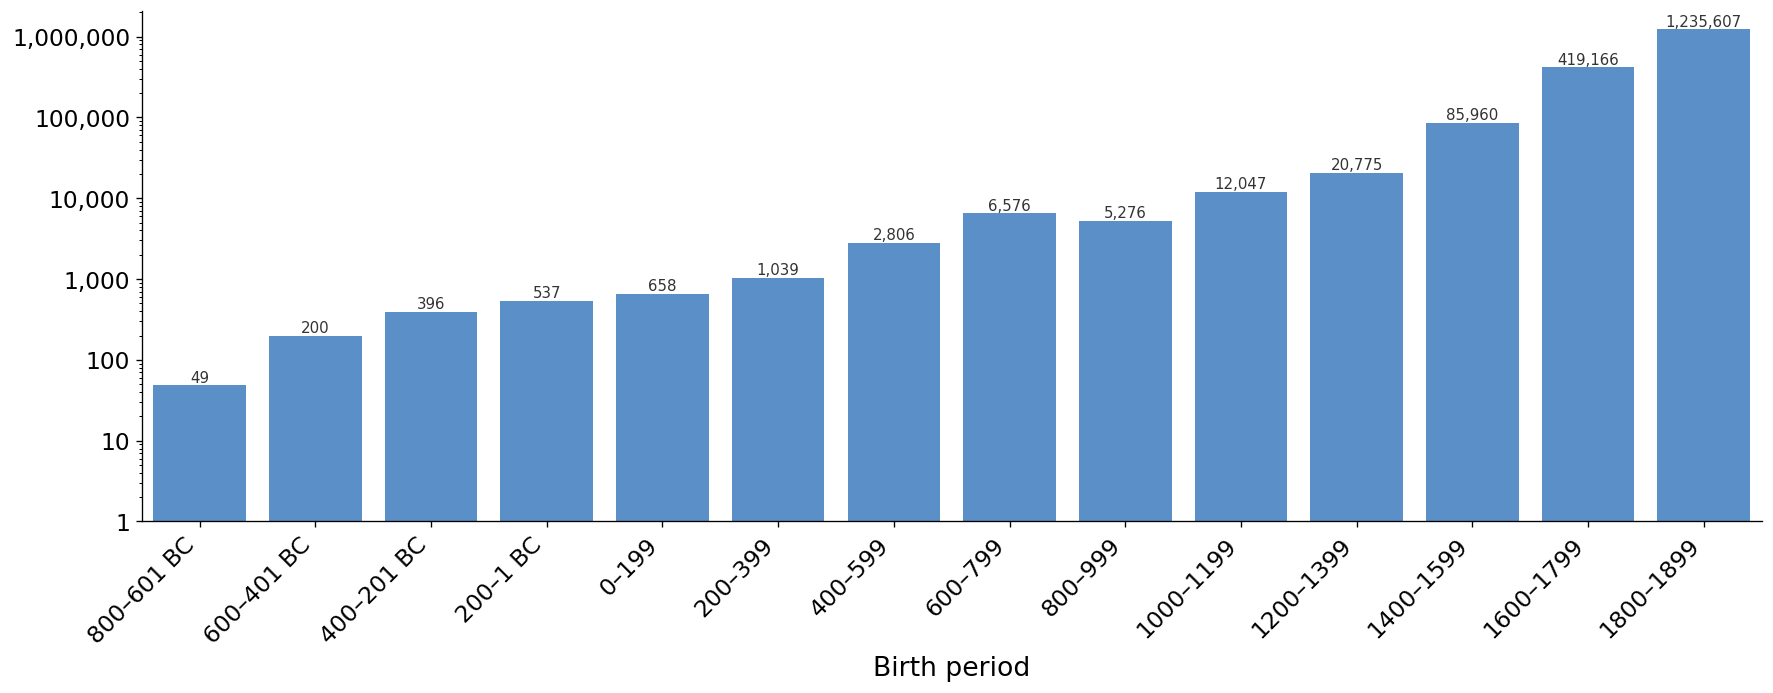

In [5]:
fig, ax = plt.subplots(figsize=FIGSIZE_WIDE)
x = (overall['birth_period'] + PERIOD_WIDTH / 2).to_numpy()
ax.bar(x, overall['individuals'], width=PERIOD_WIDTH * 0.8, color=MAIN_COLOR)
plot_counts(ax, x, overall['individuals'])
set_period_axis(ax, x, overall['birth_period'])
plt.tight_layout()
plt.show()

### Individuals per two-century birth period, by occupational category

#### Data plotted

In [6]:
overall

birth_period,Culture,Discovery/Science,Leadership,Sports/Games,Other,individuals
i64,u32,u32,u32,u32,u32,u32
-800,8,5,26,0,10,49
-600,48,48,88,2,14,200
-400,49,82,213,1,51,396
-200,53,62,339,0,83,537
0,50,73,412,3,120,658
200,91,93,582,1,272,1039
400,157,113,1198,0,1338,2806
600,535,361,999,0,4681,6576
800,453,603,1767,4,2449,5276


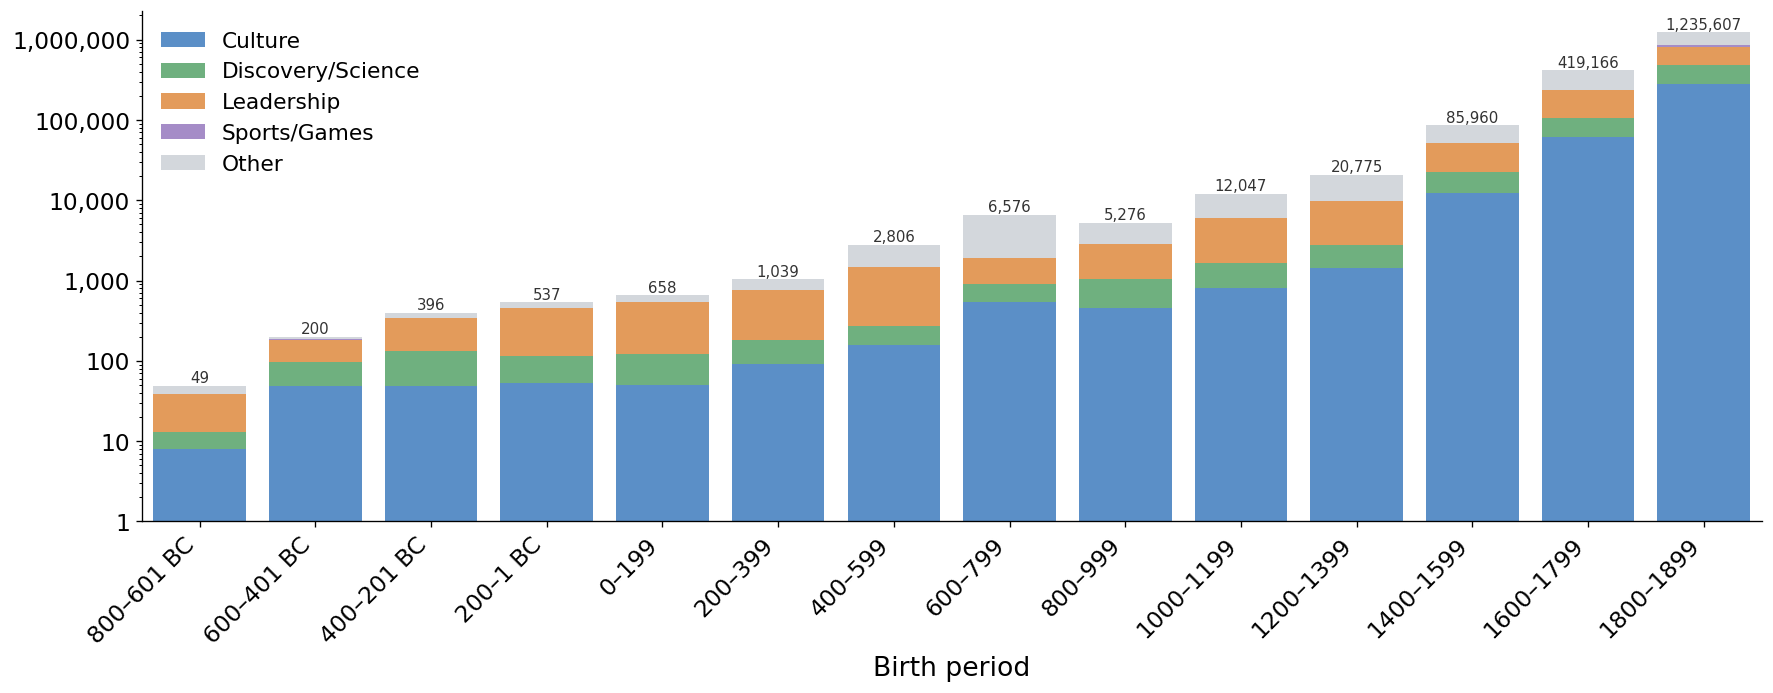

In [7]:
fig, ax = plt.subplots(figsize=FIGSIZE_WIDE)
x = (overall['birth_period'] + PERIOD_WIDTH / 2).to_numpy()
bottom = np.zeros(overall.height)
for group in STACK_ORDER:
    values = overall[group].to_numpy()
    ax.bar(x, values, bottom=bottom, width=PERIOD_WIDTH * 0.8, color=STACK_COLORS[group], label=group)
    bottom += values
plot_counts(ax, x, overall['individuals'])
set_period_axis(ax, x, overall['birth_period'])
ax.legend(loc='upper left')
plt.tight_layout()
plt.show()

### Median life expectancy of notable people per birth period

#### Data plotted

In [8]:
print('shape:', all_periods.shape)
all_periods

shape: (14, 5)


birth_period,individuals,low,median,high
i64,u32,f64,f64,f64
-800,49,40.0,60.0,75.0
-600,200,50.0,63.0,75.0
-400,396,42.0,56.0,70.0
-200,537,37.0,51.0,67.0
0,658,38.003425,55.0,70.0
200,1039,37.038356,55.0,70.0
400,2806,47.0,61.0,72.0
600,6576,49.0,60.0,70.414384
800,5276,44.0,59.0,72.0


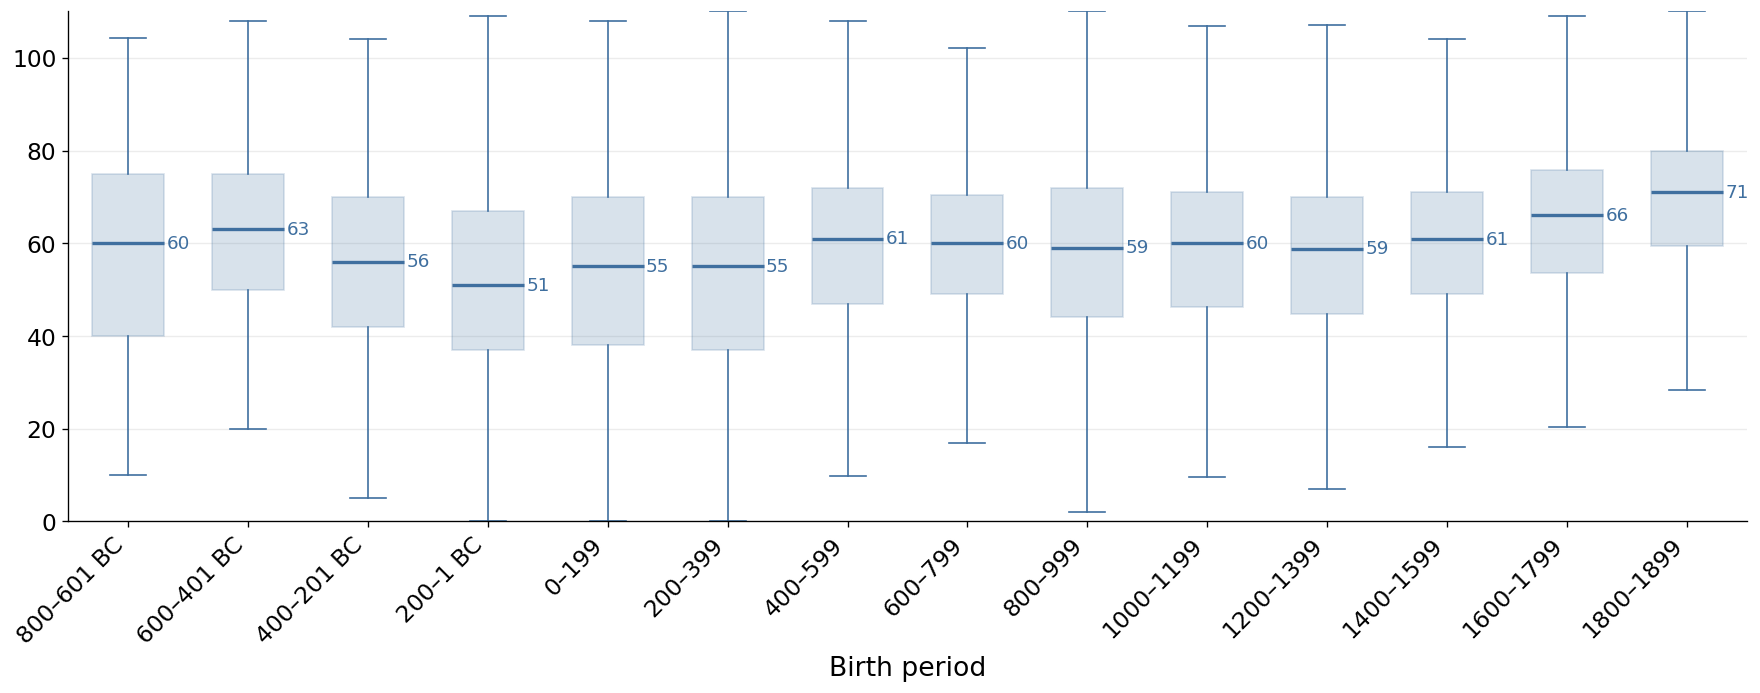

In [9]:
fig, ax = plt.subplots(figsize=FIGSIZE_WIDE)
plot_boxes(ax, lives, all_periods, MAIN_LINE_COLOR)
ax.set_xlabel('Birth period')
plt.tight_layout()
plt.show()

### Median life expectancy of notable people per birth period, by occupational category

#### Data plotted

In [10]:
occupation_periods = {}
for occupation in OCCUPATION_COLORS:
    print(occupation, end=': ')
    occupation_periods[occupation] = period_stats(lives.filter(pl.col('meta_occupation') == occupation))
pl.concat([rows.with_columns(pl.lit(occupation).alias('meta_occupation')) for occupation, rows in occupation_periods.items()])

Culture: 0 periods with fewer than 5 individuals left out (0 individuals)
Discovery/Science: 0 periods with fewer than 5 individuals left out (0 individuals)
Leadership: 0 periods with fewer than 5 individuals left out (0 individuals)
Sports/Games: 7 periods with fewer than 5 individuals left out (17 individuals)


birth_period,individuals,low,median,high,meta_occupation
i64,u32,f64,f64,f64,str
-800,8,64.25,72.5,76.25,"""Culture"""
-600,48,56.5,70.0,84.25,"""Culture"""
-400,49,60.0,66.0,76.0,"""Culture"""
-200,53,42.0,60.0,74.0,"""Culture"""
0,50,50.0,60.0,72.0,"""Culture"""
200,91,45.0,61.0,72.5,"""Culture"""
400,157,50.0,61.0,76.0,"""Culture"""
600,535,54.891781,64.0,74.0,"""Culture"""
800,453,53.0,64.0,75.0,"""Culture"""


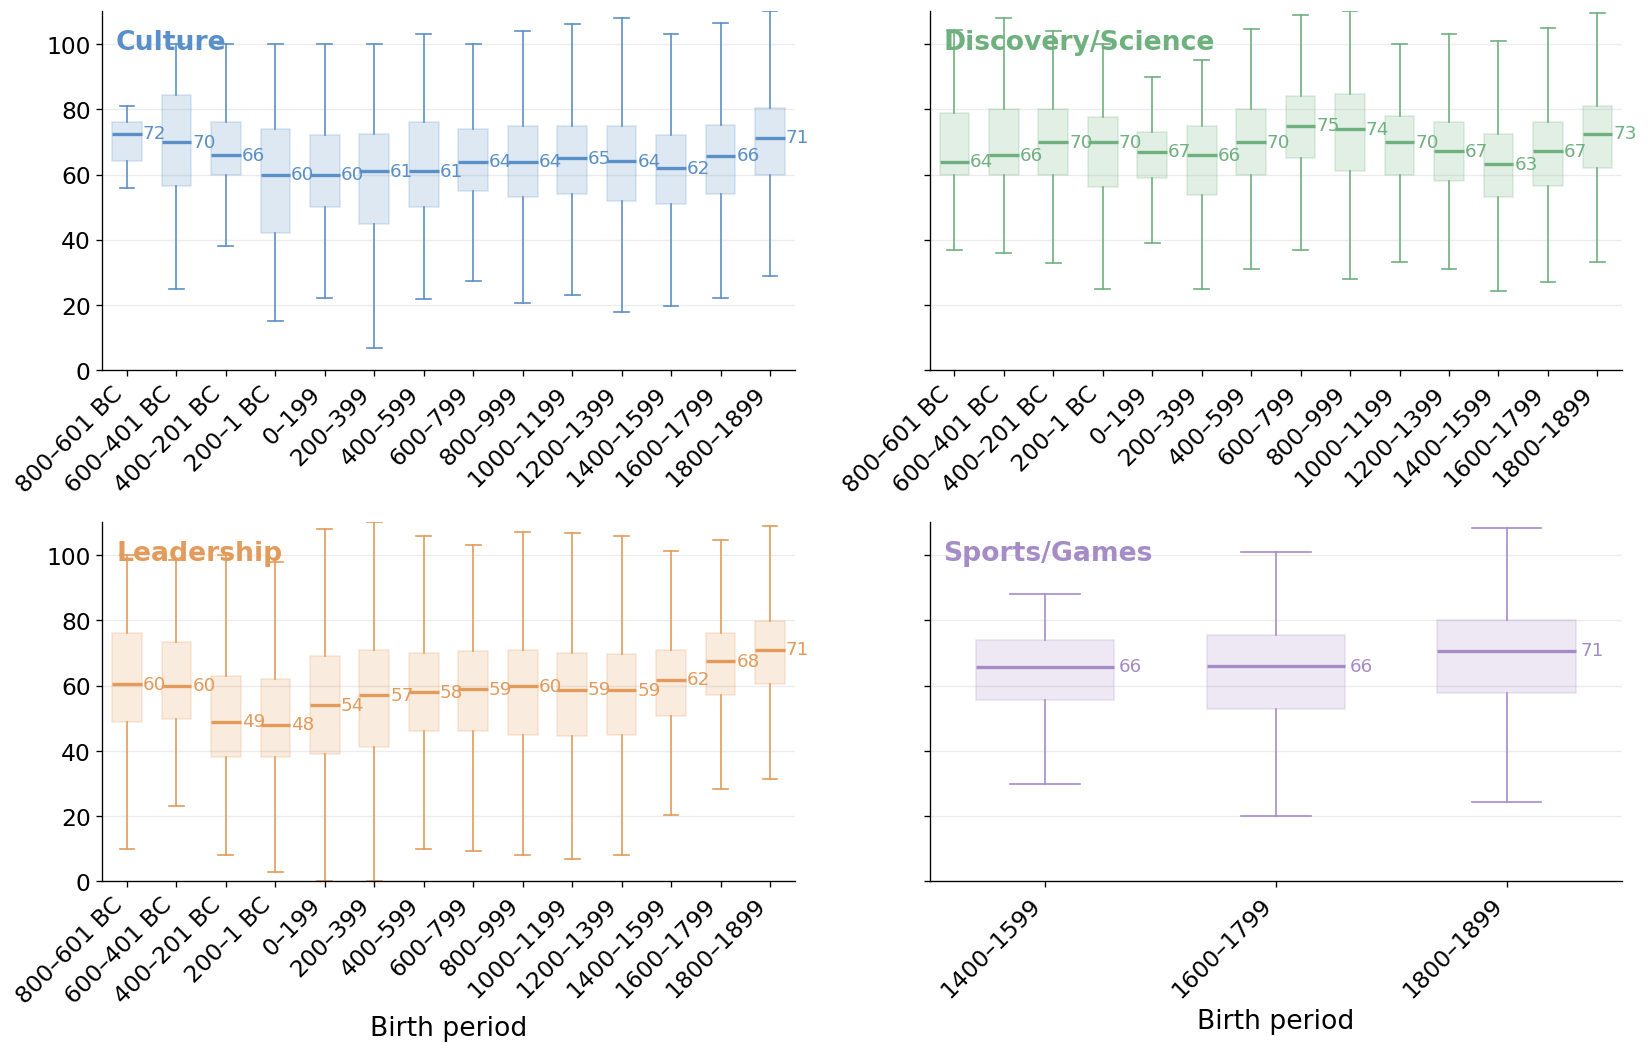

In [11]:
fig, axes = plt.subplots(2, 2, figsize=FIGSIZE_GRID, sharey=True)
for ax, (occupation, color) in zip(axes.flat, OCCUPATION_COLORS.items()):
    ax.text(0.02, 0.95, occupation, transform=ax.transAxes, fontsize=PANEL_LABEL_FONTSIZE, color=color, va='top', fontweight='bold')
    plot_boxes(ax, lives.filter(pl.col('meta_occupation') == occupation), occupation_periods[occupation], color)
for ax in axes[-1, :]:
    ax.set_xlabel('Birth period')
plt.tight_layout()
plt.show()